**Ground Truth Inpainting**

In [ ]:
import json, time
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler
from ddpm.models.unet_rad import RAD
from ddpm.diffusion.rad_inpainting_scaled import inpaint_scaled
from ddpm.diffusion.repaint_clip import sample_repaint
from ddpm.evaluation import inpainting_metrics as im

device="cuda" if torch.cuda.is_available() else "cpu"

das_data=Path("/datasets/training/earthquake/share/SISSLE_south30")
checkpoints=Path("checkpoints")
out_dir=Path("results_eval"); out_dir.mkdir(exist_ok=True)   
fs=100        # Hz
seed=0        # same seed for every method

In [ ]:
from ddpm.models.unet_ssa import DDPM as DDPM_SSA
from ddpm.models.unet_spcii import DDPM as DDPM_SPCII
from ddpm.models.unet_mamba import DDPM as DDPM_MAMBA
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler    

scheduler_ddpm=LinearNoiseScheduler(timesteps=1000,beta_start=1e-4,beta_end=0.02,device=device)

def load_prior(cls,path,key):
    m=cls(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
    m.load_state_dict(torch.load(path,map_location=device)[key])
    m.eval()
    return m

repaint_models={
    "RePaint SSA":  load_prior(DDPM_SSA,  checkpoints/"das_ddpm_earthquake_model_ssa.pth",   "model_earthquake_ssa"),
    "RePaint SPCII":load_prior(DDPM_SPCII,checkpoints/"das_ddpm_earthquake_model_spcii3.pth","model_earthquake_spcii"),   
    "RePaint Mamba":load_prior(DDPM_MAMBA,checkpoints/"das_ddpm_earthquake_model_mamba.pth", "model_earthquake_mamba"),   
}


repaint_cfg=dict(jump_length=10,jump_n_sample=3,start_resampling=300,clip_x0=1.2)   # best setting found
print("RePaint priors loaded:",list(repaint_models))

RePaint priors loaded: ['RePaint SSA', 'RePaint SPCII', 'RePaint Mamba']


In [3]:
scheduler_rad=RADNoiseScheduler(ph1_steps=1000,ph2_steps=1000,beta_start=1e-4,beta_end=0.02,device=device)
with open(checkpoints/"data_scaling.json") as f: scaling=json.load(f)
data_scale=scaling["data_scale"]

def load_rad(path,key):
    m=RAD(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
    m.load_state_dict(torch.load(path,map_location=device)[key])
    m.eval()
    return m

rad_models={"RAD v2":(load_rad(checkpoints/"das_rad_earthquake_model_v2.pth","ema_model_rad"),1.0),          # EMA
            "RAD v3":(load_rad(checkpoints/"das_rad_earthquake_model_v3.pth","ema_model_rad"),data_scale)}   # EMA + scaling
print("RAD models loaded, data_scale:",data_scale)

RAD models loaded, data_scale: 2.023162409488313


In [4]:
from torch.utils.data import DataLoader
test_loader_earthquake=DataLoader(DasDataset([das_data/"test_1001.h5"]),batch_size=16,shuffle=False)

all_test=torch.cat([b for b in test_loader_earthquake],dim=0)
rms_test=all_test.pow(2).mean(dim=(1,2,3)).sqrt()
n_win=32
idx32=torch.argsort(rms_test,descending=True)[:n_win]               # same selection as in ema_rad_scaled
X=all_test[idx32]                                                    # [32,1,256,512]
print(f"{len(all_test)} test windows | 32 loudest | RMS {rms_test[idx32].min():.3f} - {rms_test[idx32].max():.3f}")

512 test windows | 32 loudest | RMS 0.398 - 0.522


In [5]:
from ddpm.masks.rad_masks import time_strip

# A) time strips: identical to ema_rad_scaled (seed 3) -> RAD numbers must match the PDF table
g=torch.Generator(device=device).manual_seed(3)
M_strip=time_strip(n_win,256,512,device,width_range=(0.15,0.25),count_range=(1,1),generator=g).cpu()

# B) real traffic geometry from the 1111 patches (rad_traffic_removal), window k gets mask k % 4
def line_mask(H,W,segments,device,margin=16):
    """segments: list of ((t1,c1),(t2,c2),thickness) in pixels. Returns RAD mask: 1 = keep, 0 = hole."""
    yy,xx=torch.meshgrid(torch.arange(H,device=device),torch.arange(W,device=device),indexing="ij")
    hole=torch.zeros(H,W,dtype=torch.bool,device=device)
    for (t1,c1),(t2,c2),th in segments:
        dx,dy=t2-t1,c2-c1
        L2=max(dx*dx+dy*dy,1e-9)
        u=(((xx-t1)*dx+(yy-c1)*dy)/L2).clamp(0,1)
        dist=((xx-(t1+u*dx))**2+(yy-(c1+u*dy))**2).sqrt()
        hole|=dist<=(th+margin)/2
    return (~hole).float()[None]                          # [1,H,W]

traffic_segments={
    0:[((0,32),(256,16),18),((256,16),(512,3),16),((0,132),(160,148),16),((160,150),(512,168),16),((370,172),(512,174),24)],
    1:[((0,36),(160,48),24),((160,48),(512,60),22),((0,92),(256,104),14),((256,104),(512,116),16),((0,155),(256,145),14),((256,145),(512,132),14)],
    2:[((0,124),(512,118),32),((0,222),(512,232),50)],
    3:[((0,112),(512,106),26),((0,218),(512,232),52)],
}
masks4=[line_mask(256,512,traffic_segments[i],"cpu",margin=16) for i in range(4)]
M_traffic=torch.stack([masks4[k%4] for k in range(n_win)])

mask_sets={"time strip":M_strip,"traffic":M_traffic}
for name,m in mask_sets.items(): print(f"{name:10s}: {tuple(m.shape)} | hole share {100*(1-m.mean().item()):.1f} %")

time strip: (32, 1, 256, 512) | hole share 20.1 %
traffic   : (32, 1, 256, 512) | hole share 37.0 %


In [6]:
x,m=X[:4],M_traffic[:4]

perfect=im.gt_metrics(x,x.clone(),m,fs=fs)              # fill = truth -> rms 1, zcr 1, corr 1, bands 1, known_err 0
zero_fill=im.gt_metrics(x,x*m,m,fs=fs)                   # hole filled with zeros -> rms 0, corr ~0, edge_jump > 1
for name,res in [("perfect fill",perfect),("zero fill",zero_fill)]:
    print(name.ljust(13)," | ".join(f"{k} {v.mean().item():.2f}" for k,v in res.items()))

ng=im.nogt_metrics(x,x.clone(),m,fs=fs)                  # unchanged data -> fk ratios 1, coh_hole ~ coh_known
print("no-GT check  "," | ".join(f"{k} {v.mean().item():.2f}" for k,v in ng.items()))

perfect fill  rms_ratio 1.00 | zcr_ratio 1.00 | edge_corr 1.00 | edge_jump 0.95 | band_low 1.00 | band_mid 1.00 | band_high 1.00 | known_err 0.00
zero fill     rms_ratio 0.00 | zcr_ratio 0.00 | edge_corr 0.00 | edge_jump 2.75 | band_low 0.00 | band_mid 0.00 | band_high 0.00 | known_err 0.00
no-GT check   rms_hole_ring 0.99 | edge_jump 0.95 | fk_slow_ratio 1.00 | fk_fast_ratio 1.00 | coh_hole 0.84 | coh_known 0.82


In [7]:
from tqdm.auto import tqdm

batch=8      # smaller batches -> the bar moves more often (total time about the same)

def run_method(name,x,m,pbar=None):
    """Inpaint x with method `name` (RAD or RePaint), in batches. Same seed for every method."""
    out=[]
    for s in range(0,x.shape[0],batch):
        xb,mb=x[s:s+batch].to(device),m[s:s+batch].to(device)
        if name in rad_models:
            model,scale=rad_models[name]
            r,_,_=inpaint_scaled(model,scheduler_rad,xb,mb,device,scale=scale,
                                 generator=torch.Generator(device=device).manual_seed(seed))
        else:
            torch.manual_seed(seed)
            r,_,_=sample_repaint(repaint_models[name],scheduler_ddpm,xb,mb,steps_to_save=[],**repaint_cfg)
        out.append(r.cpu())
        if pbar: pbar.update(1)
    return torch.cat(out)

def result_file(name,set_name):
    return out_dir/f"{set_name}_{name}.pt".replace(" ","_")

methods=list(rad_models)+list(repaint_models)
print(methods)

['RAD v2', 'RAD v3', 'RePaint SSA', 'RePaint SPCII', 'RePaint Mamba']


In [8]:
run_sets=["traffic","time strip"]          # ["traffic"] only = half the time
n_batches=(n_win+batch-1)//batch

todo=[(s,n) for s in run_sets for n in methods if not result_file(n,s).exists()]
print(f"{len(todo)} runs to compute, {len(run_sets)*len(methods)-len(todo)} already saved")

results={s:{} for s in run_sets}
runtimes={}
pbar=tqdm(total=len(todo)*n_batches,desc="inpainting",unit="batch")
for s in run_sets:
    for name in methods:
        f=result_file(name,s)
        if f.exists():
            results[s][name]=torch.load(f)                  # already computed -> load
            continue
        pbar.set_postfix_str(f"{s} | {name}")
        t0=time.time()
        r=run_method(name,X,mask_sets[s],pbar=pbar)
        runtimes[(s,name)]=time.time()-t0
        torch.save(r,f)
        results[s][name]=r
        tqdm.write(f"{s:10s} | {name:14s} | {runtimes[(s,name)]/60:.1f} min | saved")
pbar.close()

with open(out_dir/"runtimes.json","w") as fh:
    json.dump({f"{s} | {n}":dt for (s,n),dt in runtimes.items()},fh,indent=1)

0 runs to compute, 10 already saved


inpainting: 0batch [00:00, ?batch/s]

In [29]:
with open(out_dir/"runtimes.json") as fh: rt=json.load(fh)
for k,dt in rt.items():
    print(f"{k:28s} | {dt/60:5.1f} min total | {dt/n_win:5.1f} s per window")

In [11]:
tables={}
for s in run_sets:
    m=mask_sets[s]
    tables[s]={name:im.summarize(im.gt_metrics(X,r,m,fs=fs)) for name,r in results[s].items()}
    tables[s]["truth (reference)"]=im.summarize(im.gt_metrics(X,X.clone(),m,fs=fs))
    print(f"\n===== mask set: {s} | 32 windows | mean ± std =====")
    im.print_table(tables[s],keys=["rms_ratio","zcr_ratio","edge_corr","edge_jump","band_low","band_mid","band_high"])

with open(out_dir/"tables_gt.json","w") as f:
    json.dump({s:{n:{k:list(v) for k,v in t.items()} for n,t in tab.items()} for s,tab in tables.items()},f,indent=1)


===== mask set: traffic | 32 windows | mean ± std =====
method                 |       rms_ratio |       zcr_ratio |       edge_corr |       edge_jump |        band_low |        band_mid |       band_high
RAD v2                 |   0.889 ± 0.077 |   1.124 ± 0.153 |   0.195 ± 0.058 |   0.895 ± 0.081 |   0.692 ± 0.180 |   1.023 ± 0.215 |   0.946 ± 0.213
RAD v3                 |   0.923 ± 0.091 |   1.125 ± 0.142 |   0.200 ± 0.050 |   0.959 ± 0.079 |   0.763 ± 0.210 |   1.077 ± 0.282 |   1.087 ± 0.285
RePaint SSA            |   0.516 ± 0.152 |   1.554 ± 0.399 |   0.236 ± 0.059 |   0.956 ± 0.104 |   0.268 ± 0.172 |   0.316 ± 0.171 |   0.459 ± 0.127
RePaint SPCII          |   0.920 ± 0.134 |   1.160 ± 0.229 |   0.172 ± 0.053 |   1.033 ± 0.110 |   0.845 ± 0.298 |   0.968 ± 0.298 |   0.798 ± 0.256
RePaint Mamba          |   0.610 ± 0.129 |   1.533 ± 0.346 |   0.197 ± 0.046 |   0.966 ± 0.095 |   0.319 ± 0.160 |   0.515 ± 0.199 |   0.588 ± 0.136
truth (reference)      |   1.000 ± 0.000 |   1.00

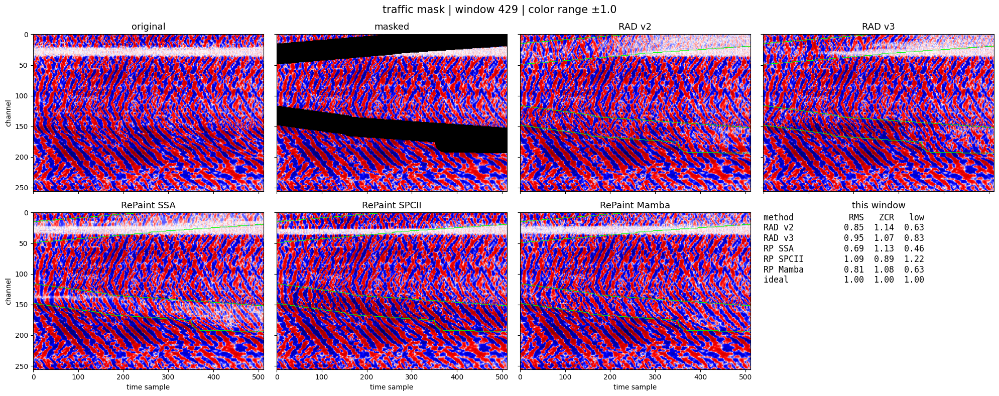

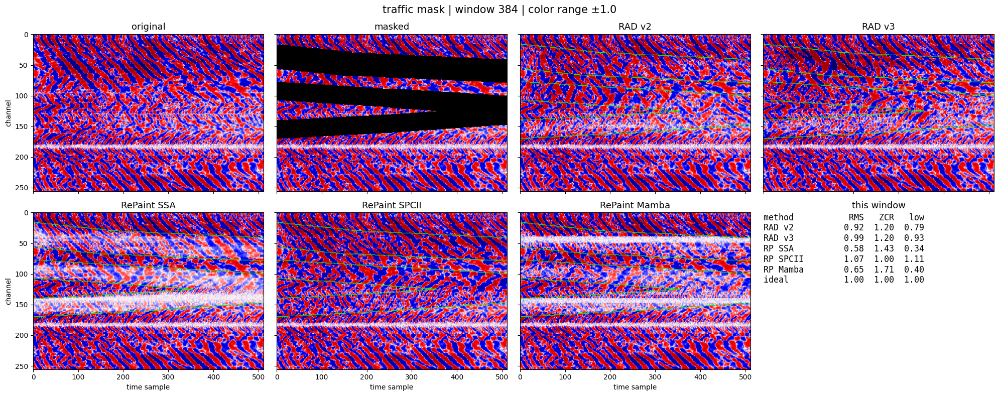

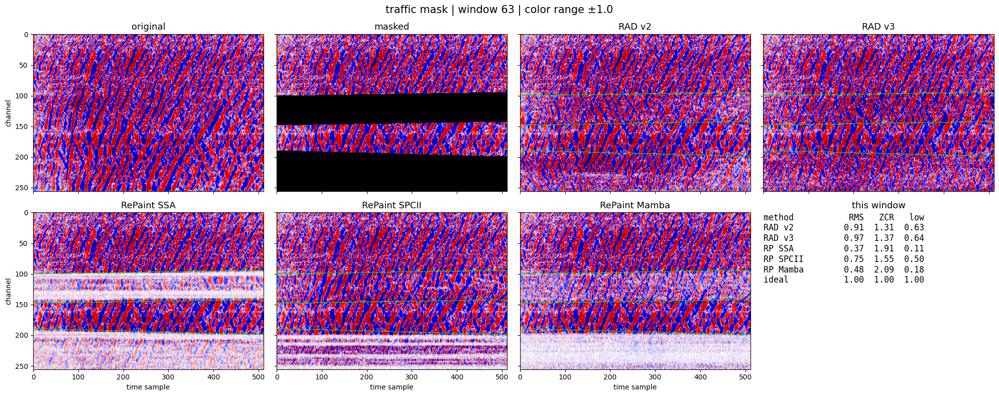

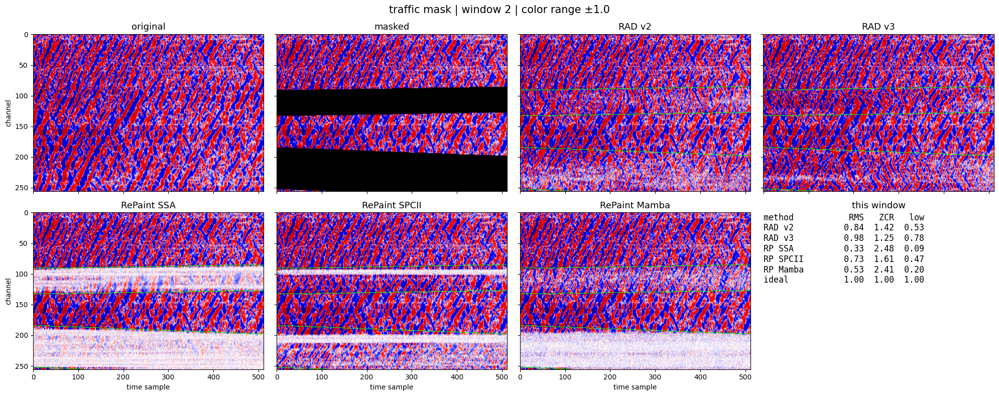

In [15]:
def show_compare(set_name,ks=(0,1,2,3),vmax=1.0,zoom=None):
    """Per window a 2x4 grid: original | masked | RAD v2 | RAD v3 / RePaint SSA | SPCII | Mamba | metrics.
    Green line = hole border. zoom = (c0,c1,t0,t1) shows only a section."""
    cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
    names=list(results[set_name])
    order=["original","masked"]+[n for n in names if n.startswith("RAD")]+[n for n in names if n.startswith("RePaint")]
    for k in ks:
        x=X[k,0]; m=mask_sets[set_name][k,0]
        masked=x.clone(); masked[m==0]=float("nan")
        imgs={"original":x,"masked":masked,**{n:results[set_name][n][k,0] for n in names}}
        mets={n:im.gt_metrics(X[k:k+1],results[set_name][n][k:k+1],mask_sets[set_name][k:k+1],fs=fs) for n in names}

        fig,axes=plt.subplots(2,4,figsize=(20,8),sharex=True,sharey=True)
        for a,title in zip(axes.flat,order):
            a.imshow(imgs[title],aspect="auto",cmap=cmap,vmin=-vmax,vmax=vmax)
            if title not in ("original","masked"):
                a.contour(m,levels=[0.5],colors="lime",linewidths=0.8)
            a.set_title(title,fontsize=13)
            if zoom: a.set_ylim(zoom[1],zoom[0]); a.set_xlim(zoom[2],zoom[3])
        for a in axes[1]: a.set_xlabel("time sample")
        for a in axes[:,0]: a.set_ylabel("channel")

        # last panel: metrics of this window
        a=axes[1,3]; a.axis("off")
        lines=[f"{'method':14s} {'RMS':>5s} {'ZCR':>5s} {'low':>5s}"]
        for n in names:
            r=mets[n]
            lines.append(f"{n.replace('RePaint ','RP '):14s} {r['rms_ratio'].item():5.2f} {r['zcr_ratio'].item():5.2f} {r['band_low'].item():5.2f}")
        lines.append(f"{'ideal':14s} {1:5.2f} {1:5.2f} {1:5.2f}")
        a.text(0.0,0.95,"\n".join(lines),family="monospace",fontsize=12,va="top")
        a.set_title("this window",fontsize=13)

        fig.suptitle(f"{set_name} mask | window {idx32[k].item()} | color range ±{vmax}",fontsize=15)
        plt.tight_layout(); plt.show()

show_compare("traffic",ks=(0,1,2,3))

In [17]:
for (s,name),dt in runtimes.items():
    print(f"{s:10s} | {name:14s} | {dt/n_win:.1f} s per window")

In [18]:
types={0:"bands inside (type 0)",1:"bands inside (type 1)",2:"band at border (type 2)",3:"band at border (type 3)"}
for t,label in types.items():
    sel=[k for k in range(n_win) if k%4==t]
    tab={n:im.summarize(im.gt_metrics(X[sel],results["traffic"][n][sel],M_traffic[sel],fs=fs)) for n in results["traffic"]}
    print(f"\n=== {label} | {len(sel)} windows ===")
    im.print_table(tab,keys=["rms_ratio","zcr_ratio","band_low"])


=== bands inside (type 0) | 8 windows ===
method                 |       rms_ratio |       zcr_ratio |        band_low
RAD v2                 |   0.905 ± 0.064 |   1.086 ± 0.105 |   0.769 ± 0.250
RAD v3                 |   0.949 ± 0.042 |   1.094 ± 0.059 |   0.856 ± 0.200
RePaint SSA            |   0.695 ± 0.042 |   1.196 ± 0.124 |   0.490 ± 0.103
RePaint SPCII          |   1.065 ± 0.041 |   0.946 ± 0.103 |   1.230 ± 0.260
RePaint Mamba          |   0.787 ± 0.026 |   1.167 ± 0.084 |   0.549 ± 0.086

=== bands inside (type 1) | 8 windows ===
method                 |       rms_ratio |       zcr_ratio |        band_low
RAD v2                 |   0.940 ± 0.036 |   1.082 ± 0.058 |   0.776 ± 0.099
RAD v3                 |   1.010 ± 0.041 |   1.068 ± 0.081 |   0.950 ± 0.148
RePaint SSA            |   0.601 ± 0.072 |   1.329 ± 0.166 |   0.336 ± 0.086
RePaint SPCII          |   0.973 ± 0.059 |   1.121 ± 0.103 |   0.853 ± 0.117
RePaint Mamba          |   0.656 ± 0.041 |   1.399 ± 0.166 |   0.35

**Traffic Removal Inpainting**

In [17]:
import importlib, ddpm.masks.patch_traffic_mask as ptm
importlib.reload(ptm); from ddpm.masks.patch_traffic_mask import patch_traffic_mask

In [9]:
from ddpm.utils.normalizer import denormalize

traffic_set=DasDataset([das_data/"test_1111.h5"])

hand_segments={**traffic_segments,
    97:[((0,110),(512,62),20),
        ((0,172),(512,196),18)],
    79:[((0,202),(512,198),22),
        ((0,243),(512,243),14)],
    93:[((0,155),(512,135),28),
        ((0,118),(512,126),16)],
    99:[((0,32),(200,22),20),((200,22),(512,8),16),
        ((0,122),(512,130),18)],
}
ids_tr=[97,79,93,0,1,2,3,99]

X_tr=torch.stack([traffic_set[i] for i in ids_tr])
M_tr=torch.stack([line_mask(256,512,hand_segments[i],"cpu",margin=16) for i in ids_tr])
mask_src=["hand"]*len(ids_tr)
for i,m in zip(ids_tr,M_tr): print(f"patch {i:4d} | hole share {100*(1-m.mean().item()):.1f} %")
torch.save({"ids":ids_tr,"M":M_tr,"segments":{i:hand_segments[i] for i in ids_tr}},out_dir/"real1111_masks.pt")

patch   97 | hole share 27.4 %
patch   79 | hole share 25.8 %
patch   93 | hole share 23.8 %
patch    0 | hole share 25.8 %
patch    1 | hole share 38.1 %
patch    2 | hole share 42.8 %
patch    3 | hole share 41.4 %
patch   99 | hole share 26.0 %


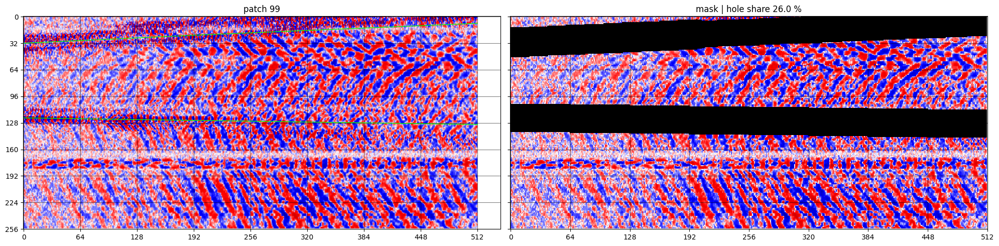

In [34]:
def show_draw(i,segments=None,margin=16):
    x=traffic_set[i][0]
    fig,ax=plt.subplots(1,2,figsize=(20,5),sharey=True)
    ax[0].imshow(x,aspect="auto",cmap="seismic",vmin=-1,vmax=1); ax[0].set_title(f"patch {i}")
    if segments:
        m=line_mask(256,512,segments,"cpu",margin=margin)[0]
        xm=x.clone(); xm[m==0]=float("nan")
        cm=plt.get_cmap("seismic").copy(); cm.set_bad("black")
        ax[1].imshow(xm,aspect="auto",cmap=cm,vmin=-1,vmax=1,interpolation="nearest")
        for (t1,c1),(t2,c2),th in segments: ax[0].plot([t1,t2],[c1,c2],"lime",lw=1)
        ax[1].set_title(f"mask | hole share {100*(1-m.mean().item()):.1f} %")
    for a in ax:
        a.set_xticks(range(0,513,64)); a.set_yticks(range(0,257,32)); a.grid(alpha=0.5,color="k")
    plt.tight_layout(); plt.show()

show_draw(99,hand_segments[99])

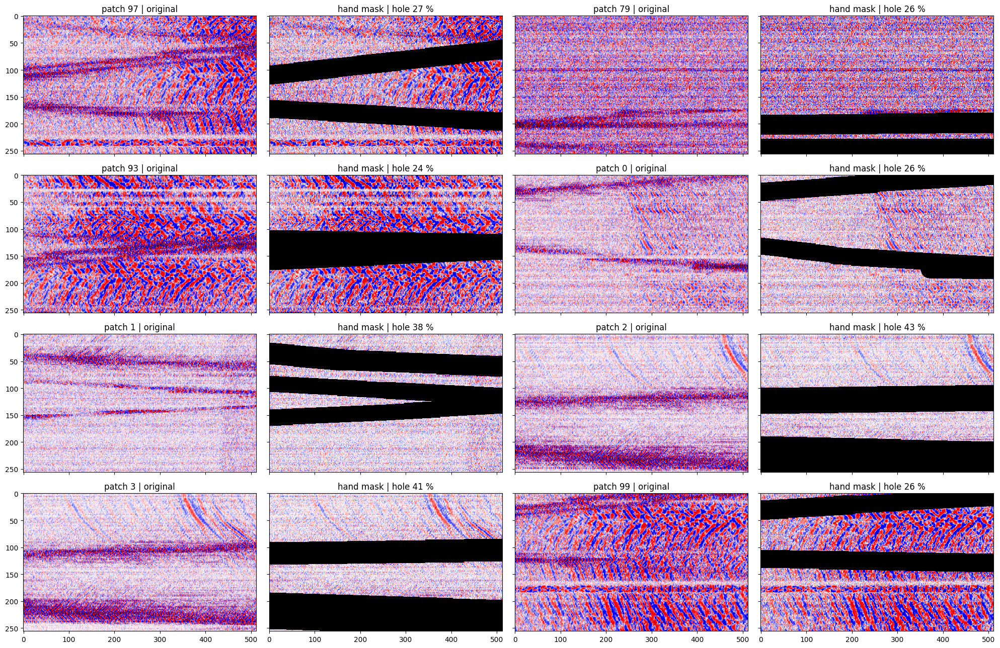

In [10]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
fig,axes=plt.subplots(4,4,figsize=(20,13),sharex=True,sharey=True)
for k in range(8):
    r,c=k//2,(k%2)*2
    x=X_tr[k,0]; xm=x.clone(); xm[M_tr[k,0]==0]=float("nan")
    axes[r,c].imshow(x,aspect="auto",cmap=cmap,vmin=-1,vmax=1); axes[r,c].set_title(f"patch {ids_tr[k]} | original")
    axes[r,c+1].imshow(xm,aspect="auto",cmap=cmap,vmin=-1,vmax=1,interpolation="nearest")
    axes[r,c+1].set_title(f"{mask_src[k]} mask | hole {100*(1-M_tr[k].mean().item()):.0f} %")
plt.tight_layout(); plt.show()

In [11]:
real_file=lambda n: out_dir/f"real1111_hand_{n}.pt".replace(" ","_")
todo=[n for n in methods if not real_file(n).exists()]
n_batches_tr=(len(ids_tr)+batch-1)//batch
print(f"{len(todo)} methods to compute, {len(methods)-len(todo)} already saved")

res_real={}
pbar=tqdm(total=len(todo)*n_batches_tr,desc="traffic removal (1111)",unit="batch")
for name in methods:
    if real_file(name).exists():
        res_real[name]=torch.load(real_file(name)); continue
    pbar.set_postfix_str(name)
    t0=time.time()
    r=run_method(name,X_tr,M_tr,pbar=pbar)
    torch.save(r,real_file(name)); res_real[name]=r
    tqdm.write(f"{name:14s} | {(time.time()-t0)/60:.1f} min | saved")
pbar.close()

0 methods to compute, 5 already saved


traffic removal (1111): 0batch [00:00, ?batch/s]

In [12]:
tab_real={n:im.summarize(im.nogt_metrics(X_tr,r,M_tr,fs=fs)) for n,r in res_real.items()}
tab_real["original (with traffic)"]=im.summarize(im.nogt_metrics(X_tr,X_tr.clone(),M_tr,fs=fs))
print(f"===== real traffic removal | {len(ids_tr)} patches of test 1111 (hand masks) | mean ± std =====")
im.print_table(tab_real,keys=["rms_hole_ring","edge_jump","fk_slow_ratio","fk_fast_ratio","coh_hole","coh_known"])

with open(out_dir/"tables_real1111_hand.json","w") as f:
    json.dump({n:{k:list(v) for k,v in t.items()} for n,t in tab_real.items()},f,indent=1)

===== real traffic removal | 8 patches of test 1111 (hand masks) | mean ± std =====
method                 |   rms_hole_ring |       edge_jump |   fk_slow_ratio |   fk_fast_ratio |        coh_hole |       coh_known
RAD v2                 |   0.883 ± 0.041 |   0.799 ± 0.074 |   0.712 ± 0.226 |   0.512 ± 0.205 |   0.711 ± 0.078 |   0.690 ± 0.090
RAD v3                 |   0.906 ± 0.072 |   0.840 ± 0.095 |   0.711 ± 0.210 |   0.519 ± 0.203 |   0.703 ± 0.072 |   0.690 ± 0.090
RePaint SSA            |   0.523 ± 0.078 |   0.883 ± 0.099 |   0.633 ± 0.192 |   0.432 ± 0.194 |   0.666 ± 0.062 |   0.690 ± 0.090
RePaint SPCII          |   0.745 ± 0.180 |   0.905 ± 0.134 |   0.713 ± 0.260 |   0.473 ± 0.212 |   0.708 ± 0.076 |   0.690 ± 0.090
RePaint Mamba          |   0.685 ± 0.089 |   0.904 ± 0.080 |   0.704 ± 0.161 |   0.457 ± 0.192 |   0.652 ± 0.065 |   0.690 ± 0.090
original (with traffic) |   1.634 ± 0.514 |   0.905 ± 0.091 |   1.000 ± 0.000 |   1.000 ± 0.000 |   0.659 ± 0.043 |   0.690 ± 0.09

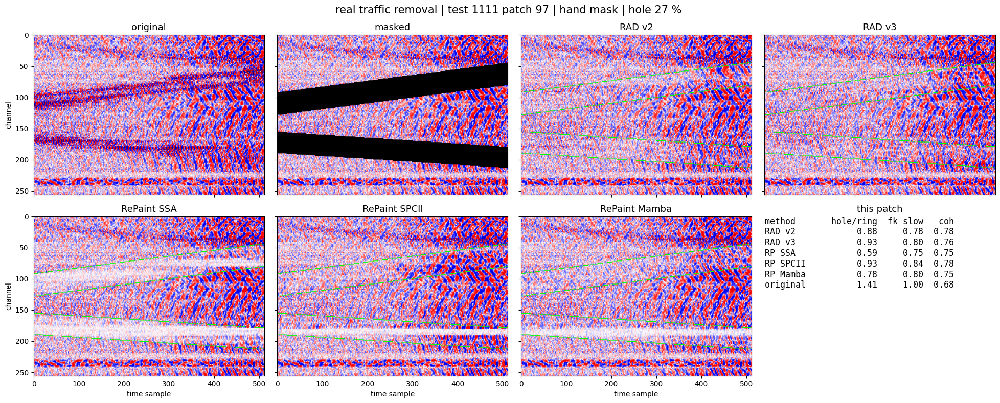

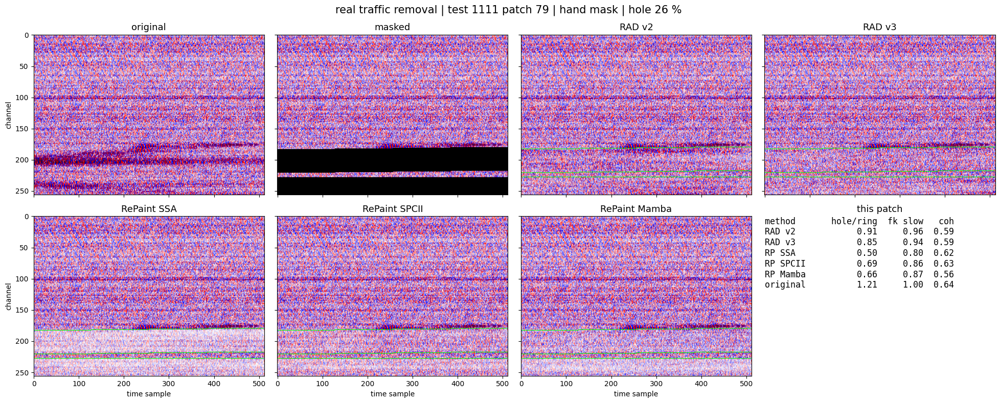

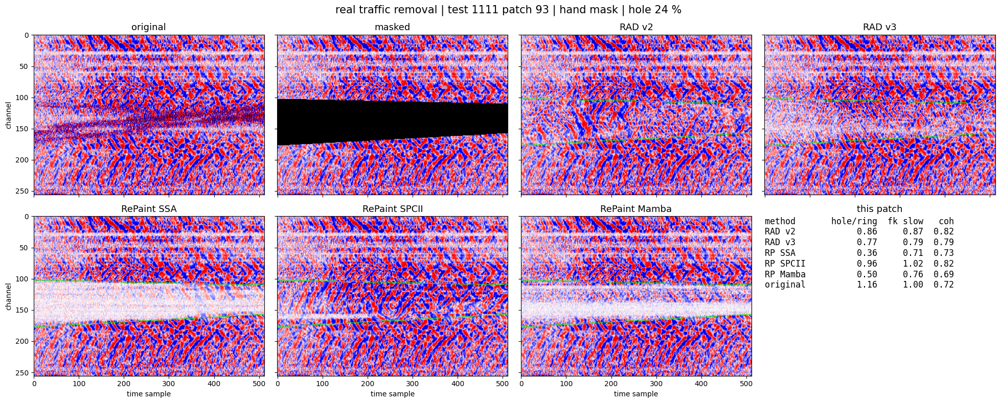

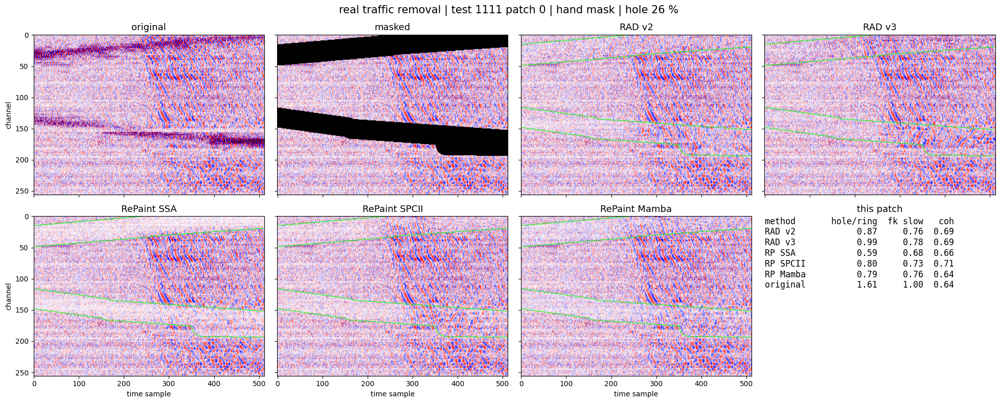

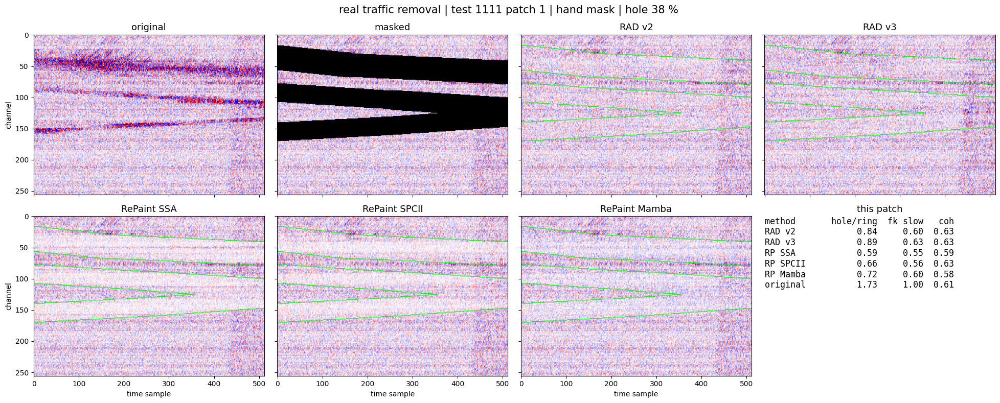

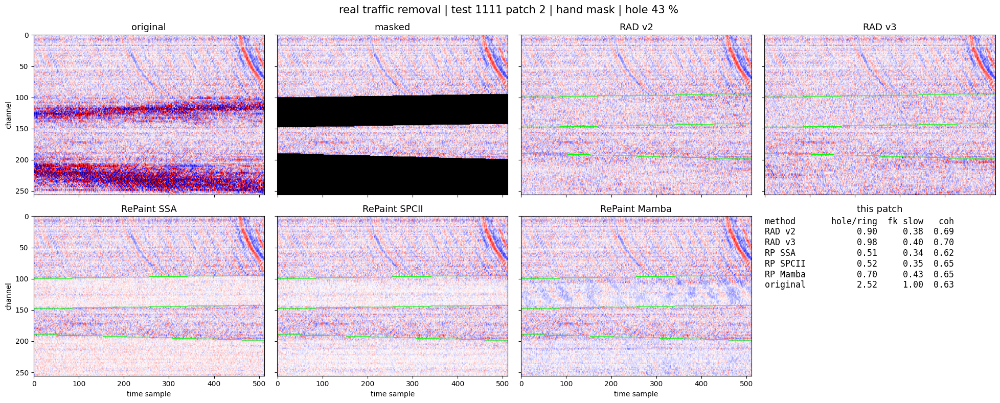

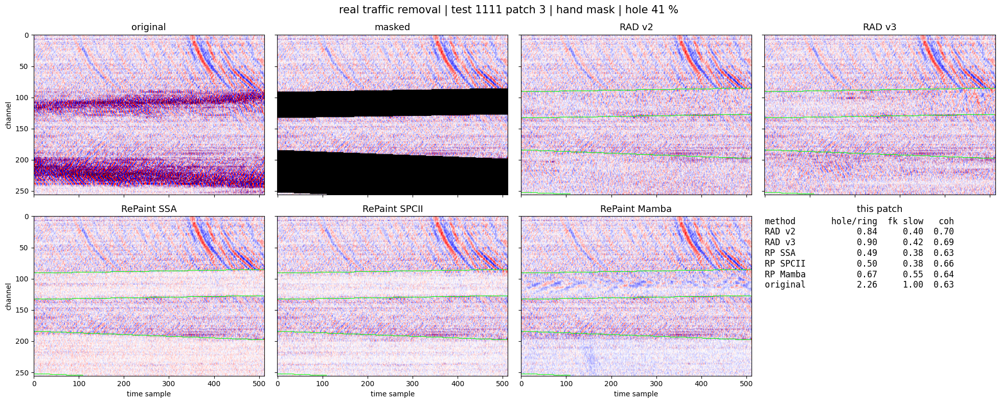

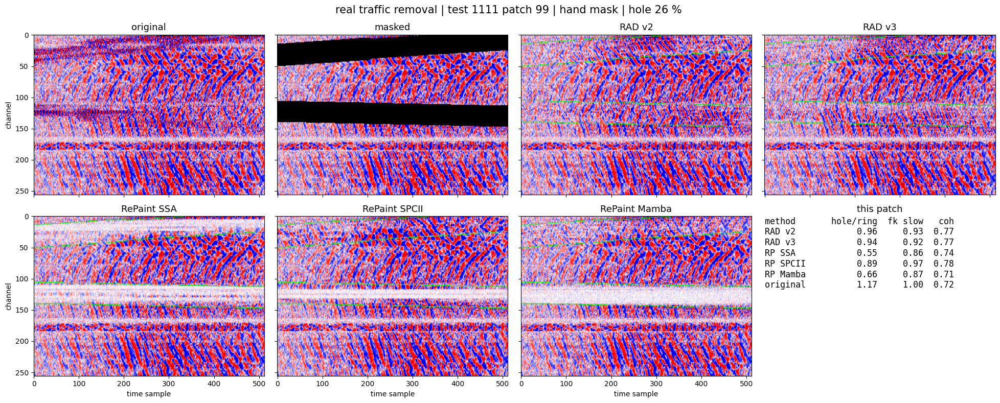

In [13]:
def show_real(ks=range(8),vmax=1.0,zoom=None):
    """Per patch: original | mask | RAD v2 | RAD v3 / RePaint SSA | SPCII | Mamba | metrics (no ground truth)."""
    cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
    names=list(res_real)
    order=["original","masked"]+[n for n in names if n.startswith("RAD")]+[n for n in names if n.startswith("RePaint")]
    for k in ks:
        x=X_tr[k,0]; m=M_tr[k,0]
        xm=x.clone(); xm[m==0]=float("nan")
        imgs={"original":x,"masked":xm,**{n:res_real[n][k,0] for n in names}}
        mets={n:im.nogt_metrics(X_tr[k:k+1],res_real[n][k:k+1],M_tr[k:k+1],fs=fs) for n in names}
        fig,axes=plt.subplots(2,4,figsize=(20,8),sharex=True,sharey=True)
        for a,t in zip(axes.flat,order):
            a.imshow(imgs[t],aspect="auto",cmap=cmap,vmin=-vmax,vmax=vmax)
            if t not in ("original","masked"): a.contour(m,levels=[0.5],colors="lime",linewidths=0.8)
            a.set_title(t,fontsize=13)
            if zoom: a.set_ylim(zoom[1],zoom[0]); a.set_xlim(zoom[2],zoom[3])
        a=axes[1,3]; a.axis("off")
        lines=[f"{'method':12s} {'hole/ring':>9s} {'fk slow':>8s} {'coh':>5s}"]
        for n in names:
            r=mets[n]
            lines.append(f"{n.replace('RePaint ','RP '):12s} {r['rms_hole_ring'].item():9.2f} {r['fk_slow_ratio'].item():8.2f} {r['coh_hole'].item():5.2f}")
        o=im.nogt_metrics(X_tr[k:k+1],X_tr[k:k+1].clone(),M_tr[k:k+1],fs=fs)
        lines.append(f"{'original':12s} {o['rms_hole_ring'].item():9.2f} {o['fk_slow_ratio'].item():8.2f} {o['coh_hole'].item():5.2f}")
        a.text(0,0.95,"\n".join(lines),family="monospace",fontsize=12,va="top"); a.set_title("this patch",fontsize=13)
        for a in axes[1]: a.set_xlabel("time sample")
        for a in axes[:,0]: a.set_ylabel("channel")
        fig.suptitle(f"real traffic removal | test 1111 patch {ids_tr[k]} | hand mask | hole {100*(1-M_tr[k].mean().item()):.0f} %",fontsize=15)
        plt.tight_layout(); plt.show()

show_real()

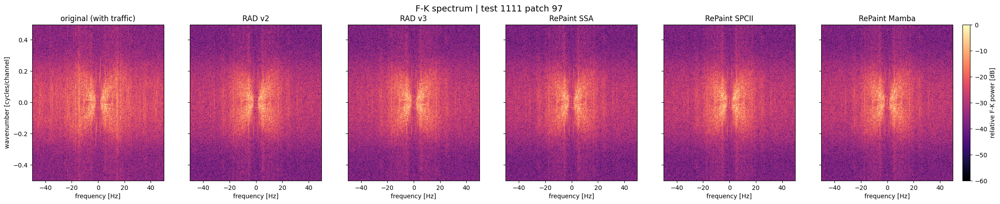

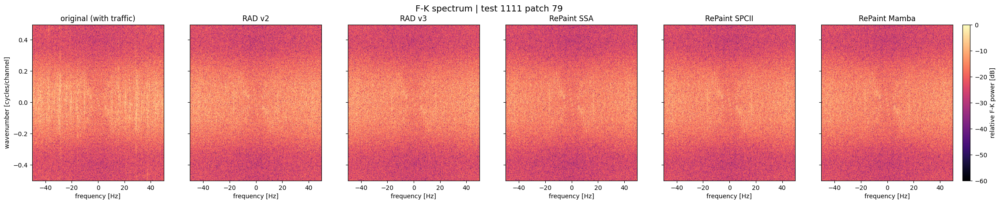

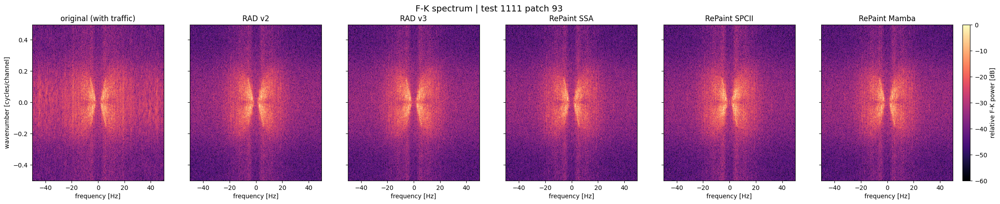

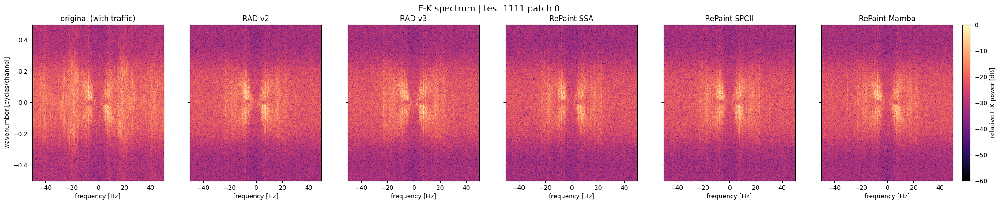

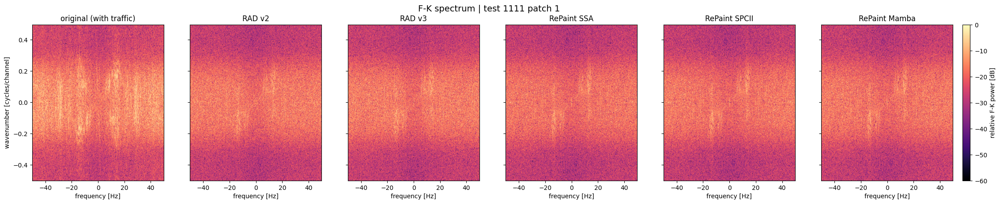

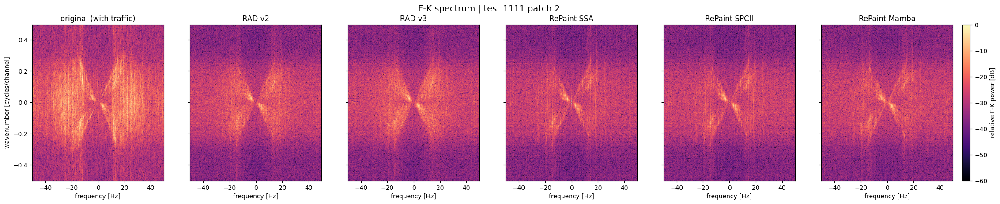

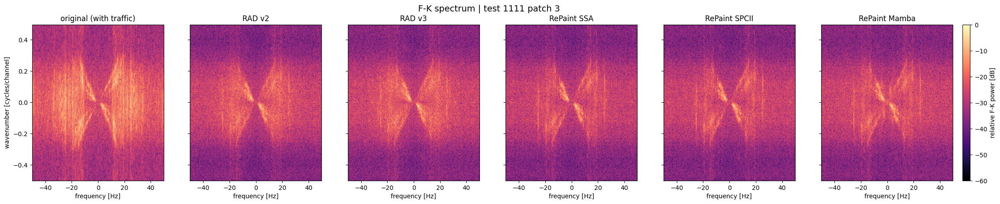

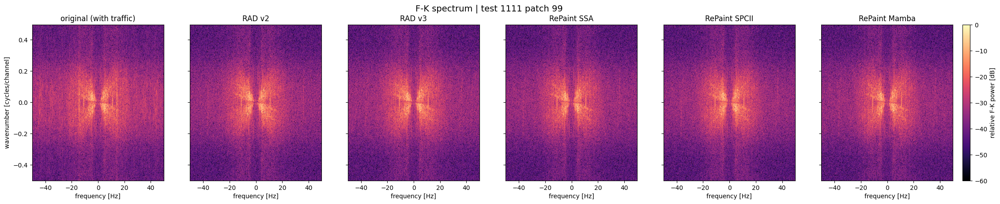

In [14]:
def fk_db(x2d,ref=None):
    X=x2d-x2d.mean()
    P=torch.fft.fftshift(torch.fft.fft2(X).abs().pow(2)).numpy()
    ref=P.max() if ref is None else ref
    return 10*np.log10(P/ref+1e-12),ref

def show_fk_patch(k,names=None,vmin=-60):
    names=names or list(res_real)
    H_,W_=X_tr.shape[-2:]
    kk=np.fft.fftshift(np.fft.fftfreq(H_,d=1.0))
    ff=np.fft.fftshift(np.fft.fftfreq(W_,d=1.0/fs))
    D0,ref=fk_db(X_tr[k,0])
    panels=[("original (with traffic)",D0)]+[(n,fk_db(res_real[n][k,0],ref)[0]) for n in names]
    fig,axes=plt.subplots(1,len(panels),figsize=(4.6*len(panels),4.6),sharey=True)
    for a,(t,D) in zip(axes,panels):
        im_=a.imshow(D,aspect="auto",cmap="magma",vmin=vmin,vmax=0,origin="lower",
                     extent=[ff[0],ff[-1],kk[0],kk[-1]])
        a.set_title(t,fontsize=12); a.set_xlabel("frequency [Hz]")
    axes[0].set_ylabel("wavenumber [cycles/channel]")
    fig.colorbar(im_,ax=axes,fraction=0.015,pad=0.01,label="relative F-K power [dB]")
    fig.suptitle(f"F-K spectrum | test 1111 patch {ids_tr[k]}",fontsize=14)
    plt.show()

for k in range(len(ids_tr)):
    show_fk_patch(k)